## AI - AUGMENTED ZERO TRUST FRAMEWORK FOR BFSI

### Import the Libraries

In [ ]:
from google.colab import drive
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from datetime import datetime, timedelta
from sklearn.metrics import f1_score
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.ensemble import IsolationForest
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from joblib import dump
from joblib import load


In [ ]:
sns.set(style="whitegrid") #Set Seaborn plot style to "whitegrid" for cleaner and more readable visualizations

It indicates that all subsequent plots will have a white background with gridlines, which improves readability for charts in reports and posters.

<h1 align = 'center'>Exploratory Data Analysis (EDA) </h1>

<hr>

### 1. Load the Files
#### *1.1 Mount the Drive*

In [ ]:
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


* Mounting Google Drive connects persistent cloud storage to the Colab
runtime, allowing datasets and outputs to be accessed like local files.
* This ensures data persistence across sessions and supports a clean, reproducible ML workflow.

#### *1.2 Fetch the data from Drive*

In [ ]:
ai_zta_path = '/content/drive/MyDrive/ai_zta_logs.csv'
traditional_zta_path = '/content/drive/MyDrive/traditional_zta_logs.csv'

df_ai = pd.read_csv(ai_zta_path)
df_traditional = pd.read_csv(traditional_zta_path)

*   This command loads the synthetic Zero Trust access log dataset from Google Drive into a Pandas DataFrame.
* It converts raw CSV data into a structured format required for analysis, preprocessing, and model training.

#### *1.3 Count of Rows and Columns*

In [ ]:
print("AI-ZTA dataset shape:", df_ai.shape)
print("Traditional ZTA dataset shape:", df_traditional.shape)

AI-ZTA dataset shape: (200000, 12)
Traditional ZTA dataset shape: (200000, 12)


AI-ZTA Dataset:
* Contains 200,000 records and 12 features.
* Each record represents a simulated user interaction.
* Includes trust scores computed by the AI, behavior anomalies, and the resulting access decisions (allow, step-up, restrict, block).
* Purpose: To show how an AI-based Zero Trust system adapts to user behavior and environmental risk.

Traditional ZTA Dataset:
* Contains 200,000 records and 12 features.
* Each record represents a simulated user interaction.
* Includes trust scores calculated using static rules and the resulting access decisions.
* Purpose: To provide a baseline using a traditional, rule-based Zero Trust system for comparison against the AI-based approach.

#### *1.4 Read the Data (First 5 Columns)*

In [ ]:
# Preview of the ai_ZTA
display(df_ai.head())

# Preview of the traditional_ZTA
display(df_traditional.head())

,timestamp,user_id,user_type,role,auth_method,device_posture,location_risk,network_risk,behavior_anomaly,historical_trust,computed_trust,action
0,2026-01-08 17:51:49.302275+00:00,7da7a9b6-5681-4b7b-bc04-df97188a0461,customer,retail,password,unknown,low,high,0.37,67,43.24,restrict
1,2026-01-08 17:51:49.302365+00:00,8edcdd1c-929d-4312-84c2-f10f1a1ad7e9,vendor,support,mfa,jailbroken,high,low,0.71,68,32.43,block
2,2026-01-08 17:51:49.302418+00:00,485e4e11-9567-4019-b9e3-90642e9f761e,employee,it_admin,mfa,compliant,low,medium,0.28,67,73.97,step-up
3,2026-01-08 17:51:49.302466+00:00,825daba8-d3d0-4d0d-a49c-d687c008dc93,vendor,support,password,compliant,medium,high,0.80,62,28.00,block
4,2026-01-08 17:51:49.302544+00:00,5a94b611-a601-4ebc-9f29-dda804b218ad,employee,it_admin,mfa,unknown,high,medium,0.33,90,69.98,step-up


,timestamp,user_id,user_type,role,auth_method,device_posture,location_risk,network_risk,behavior_anomaly,historical_trust,computed_trust,action
0,2026-01-08 17:54:16.601456+00:00,160db6c7-3b3d-4d36-aa68-c47b021fe065,employee,manager,mfa,compliant,low,medium,0.0,50,70,allow
1,2026-01-08 17:54:16.601513+00:00,ecb27ed8-839d-4235-9681-b06782350e2a,employee,teller,mfa,compliant,high,low,0.0,50,60,step-up
2,2026-01-08 17:54:16.601542+00:00,c9ae149b-13b2-4289-b715-1f043c6a57d9,customer,retail,password,unknown,low,medium,0.0,50,45,step-up
3,2026-01-08 17:54:16.601561+00:00,50b9499b-710e-4884-8875-3d0f378197e4,employee,it_admin,mfa,compliant,medium,low,0.0,50,70,allow
4,2026-01-08 17:54:16.601584+00:00,cd03a2a7-09a2-4c9d-82ca-ce03c24cf392,vendor,auditor,biometric,unknown,high,high,0.0,50,40,step-up


AI-ZTA Dataset:
* Shows the first few user interactions simulated using the AI-driven Zero Trust system.
* Includes trust scores computed by the AI, behavioral anomalies, and the resulting access decisions (allow, step-up, restrict, block).
* Purpose: To give a quick glance at the data structure and understand what each column represents.

Traditional ZTA Dataset:
* Shows the first few user interactions simulated using the rule-based Zero Trust system.
* Includes trust scores calculated using fixed rules and the corresponding access decisions.
* Purpose: To compare how traditional ZTA data is structured relative to AI-ZTA, highlighting the absence of behavior-based anomalies.

#### *1.5 Checking Data Types and Missing Values*

In [ ]:
# AI-ZTA info
print("AI-ZTA Dataset Info:")
df_ai.info()

# Traditional ZTA info
print("\nTraditional ZTA Dataset Info:")
df_traditional.info()

AI-ZTA Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   timestamp         200000 non-null  object 
 1   user_id           200000 non-null  object 
 2   user_type         200000 non-null  object 
 3   role              200000 non-null  object 
 4   auth_method       200000 non-null  object 
 5   device_posture    200000 non-null  object 
 6   location_risk     200000 non-null  object 
 7   network_risk      200000 non-null  object 
 8   behavior_anomaly  200000 non-null  float64
 9   historical_trust  200000 non-null  int64  
 10  computed_trust    200000 non-null  float64
 11  action            200000 non-null  object 
dtypes: float64(2), int64(1), object(9)
memory usage: 18.3+ MB

Traditional ZTA Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 12 c

* This step inspects the type of data stored in each column (e.g., numeric, text) for both datasets.
* It also checks for missing or null values that could affect analysis.
* AI-ZTA Dataset: Confirms that columns like computed_trust and behavior_anomaly are numeric and ready for analysis.
* Traditional ZTA Dataset: Confirms that trust scores and categorical columns are correctly formatted, and highlights that there are no behavioral anomaly values since it’s rule-based.
* Purpose: Ensures the datasets are clean and consistent before performing detailed EDA or visual comparisons.

#### *1.6 Summary statistics for numerical features*

In [ ]:
# AI-ZTA
print("AI-ZTA Numerical Summary:")
display(df_ai.describe().round(2))

# Traditional ZTA
print("Traditional ZTA Numerical Summary:")
display(df_traditional.describe().round(2))

AI-ZTA Numerical Summary:


,behavior_anomaly,historical_trust,computed_trust
count,200000.00,200000.00,200000.00
mean,0.43,67.52,49.13
std,0.21,13.27,20.35
min,0.00,45.00,0.00
25%,0.27,56.00,34.80
50%,0.42,68.00,49.22
75%,0.58,79.00,63.49
max,0.99,90.00,100.00


Traditional ZTA Numerical Summary:


,behavior_anomaly,historical_trust,computed_trust
count,200000.0,200000.0,200000.00
mean,0.0,50.0,46.69
std,0.0,0.0,15.28
min,0.0,50.0,10.00
25%,0.0,50.0,35.00
50%,0.0,50.0,45.00
75%,0.0,50.0,60.00
max,0.0,50.0,75.00


* This step provides a statistical overview of the numerical columns in both datasets, including computed_trust, behavior_anomaly (AI-ZTA only), and historical_trust.
* Key statistics include:
    * Mean: The average trust score or anomaly value, showing the general trend.
    * Median (50%): The middle value, useful to see if the data is balanced or skewed.
    * Minimum and Maximum: The lowest and highest values, showing the range.
    * Standard Deviation: How much the values vary from the mean, indicating variability.
    * Quartiles (25% & 75%): The range where the middle 50% of values lie, highlighting typical user behavior.

* AI-ZTA Dataset: Shows variability in trust and behavioral anomaly, reflecting adaptive, behavior-aware decisions.
* Traditional ZTA Dataset: Trust scores are more fixed and rule-based, with no behavioral anomaly data, serving as a baseline.
* Purpose: To quickly understand the distribution and variability of key metrics before deeper analysis or visualization.

#### *1.7 Categorical feature overview*

In [ ]:
# Count of actions for AI-ZTA
print("AI-ZTA Action Distribution:")
display(df_ai['action'].value_counts())

# Count of actions for Traditional ZTA
print("Traditional ZTA Action Distribution:")
display(df_traditional['action'].value_counts())

AI-ZTA Action Distribution:


,count
action,
restrict,81904
step-up,60434
block,50585
allow,7077


Traditional ZTA Action Distribution:


,count
action,
step-up,118518
block,61669
allow,19813


* This step looks at how many times each access decision occurred in the two systems.
* AI-ZTA Dataset:
    * restrict: 81,904 times
    * step-up: 60,434 times
    * block: 50,585 times
    * allow: 7,077 times
* Interpretation: The AI system is more cautious, giving fewer full allow decisions and adjusting access dynamically based on trust and behavioral anomalies.

* Traditional ZTA Dataset:
    * step-up: 118,518 times
    * block: 61,669 times
    * allow: 19,813 times
* Interpretation: The rule-based system tends to allow more users or require step-up actions based on static thresholds, without adapting to behavior.

Key Takeaway:
* AI-ZTA shows more nuanced, adaptive access control, while Traditional ZTA relies on fixed rules, making the AI system more responsive to potential risks.

#### *1.8 Computed Trust Score Distribution*

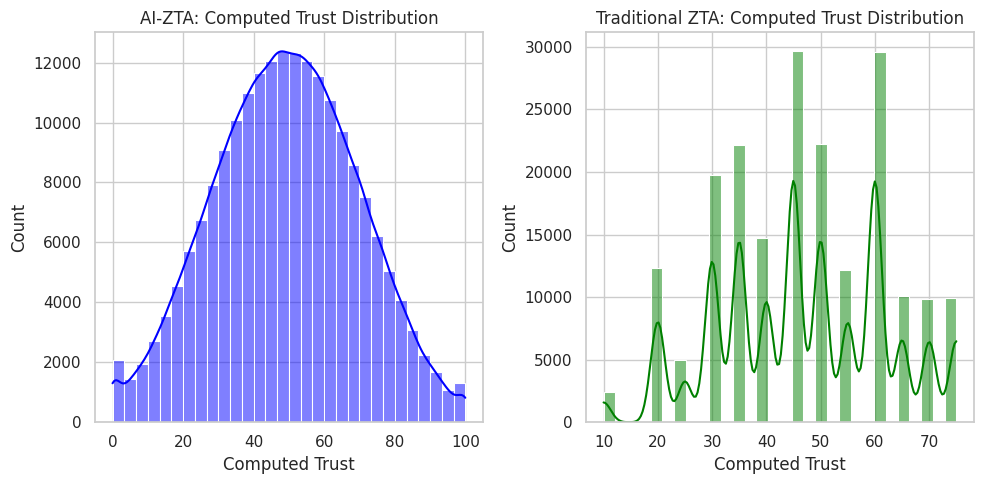

In [ ]:
plt.figure(figsize=(10,5))

# AI-ZTA trust distribution
plt.subplot(1,2,1)
sns.histplot(df_ai['computed_trust'], bins=30, kde=True, color='blue')
plt.title('AI-ZTA: Computed Trust Distribution')
plt.xlabel('Computed Trust')
plt.ylabel('Count')

# Traditional ZTA trust distribution
plt.subplot(1,2,2)
sns.histplot(df_traditional['computed_trust'], bins=30, kde=True, color='green')
plt.title('Traditional ZTA: Computed Trust Distribution')
plt.xlabel('Computed Trust')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

AI-ZTA (Left Plot):
* Trust scores are spread across a wide range.
* The AI system adjusts trust dynamically based on user behavior, device posture, and risk factors.
* This makes the system flexible and responsive, giving more accurate assessments of risk.

Traditional ZTA (Right Plot):
* Trust scores are more clustered around certain values.
* The system uses fixed rules without considering behavior or context.
* This makes trust evaluation less adaptive and more predictable, with fewer variations.

Key Takeaway:
* The AI-ZTA system is more intelligent and adaptive, while Traditional ZTA is rigid and rule-based.
* This visualization clearly shows why AI improves trust assessment and security decisions.

#### *1.9 Device Posture and Access Decisions*

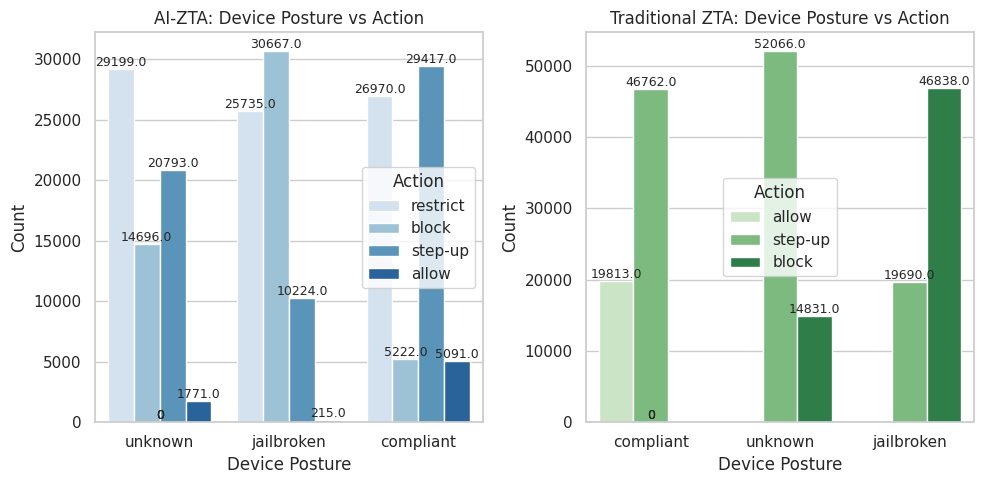

In [ ]:
plt.figure(figsize=(10,5))

# AI-ZTA
plt.subplot(1,2,1)
ax1 = sns.countplot(x='device_posture', hue='action', data=df_ai, palette='Blues')
plt.title('AI-ZTA: Device Posture vs Action')
plt.xlabel('Device Posture')
plt.ylabel('Count')
plt.legend(title='Action')

# Add counts on top of bars
for p in ax1.patches:
    height = p.get_height()
    ax1.annotate(f'{height}', (p.get_x() + p.get_width()/2., height),
                 ha='center', va='bottom', fontsize=9, rotation=0)

# Traditional ZTA
plt.subplot(1,2,2)
ax2 = sns.countplot(x='device_posture', hue='action', data=df_traditional, palette='Greens')
plt.title('Traditional ZTA: Device Posture vs Action')
plt.xlabel('Device Posture')
plt.ylabel('Count')
plt.legend(title='Action')

# Add counts on top of bars
for p in ax2.patches:
    height = p.get_height()
    ax2.annotate(f'{height}', (p.get_x() + p.get_width()/2., height),
                 ha='center', va='bottom', fontsize=9, rotation=0)

plt.tight_layout()
plt.show()

AI-ZTA (Left Plot):
* The AI system is more cautious and adaptive.
* Even devices that are compliant may get restrict or step-up actions if other risk factors exist.
* Non-compliant (jailbroken/unknown) devices often get block actions.
* Allow actions are relatively low, showing the AI considers multiple risk signals, not just device posture.

Traditional ZTA (Right Plot):
* Decisions are more predictable and rule-based.
* Compliant devices often get step-up or allow actions.
* Non-compliant devices mostly get block.
* The system does not dynamically adjust based on behavior or anomalies.

Key Takeaway:
* AI-ZTA is adaptive, reacting to real-time risks and behavioral anomalies.
* Traditional ZTA is rigid, relying mainly on fixed rules.
* This comparison clearly shows why AI improves access control and security.

#### *1.10 User Role and Access Decisions*

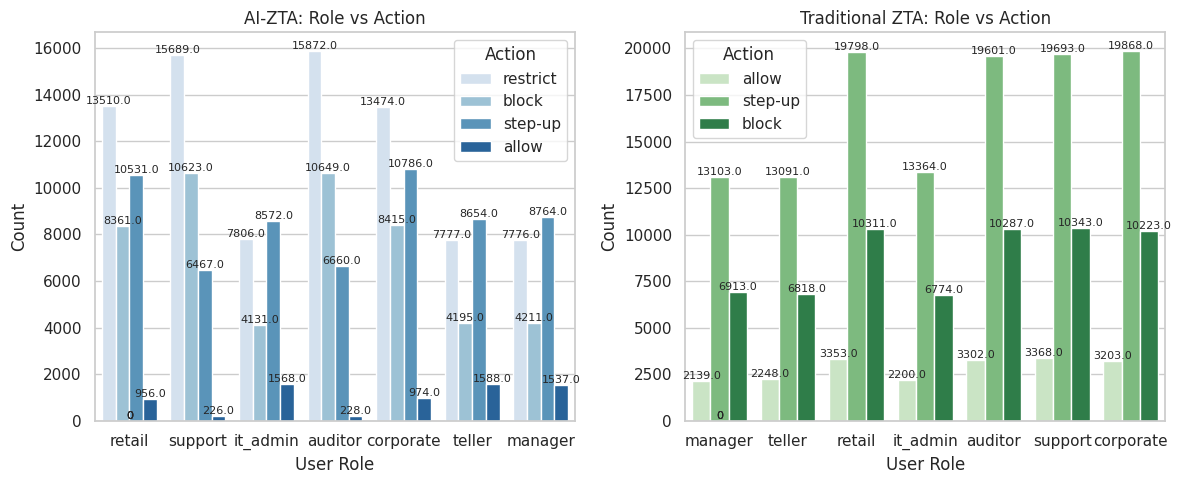

In [ ]:
plt.figure(figsize=(12,5))

# AI-ZTA
plt.subplot(1,2,1)
ax1 = sns.countplot(x='role', hue='action', data=df_ai, palette='Blues')
plt.title('AI-ZTA: Role vs Action')
plt.xlabel('User Role')
plt.ylabel('Count')
plt.legend(title='Action')

# Add counts on top of bars
for p in ax1.patches:
    height = p.get_height()
    ax1.annotate(f'{height}', (p.get_x() + p.get_width()/2., height),
                 ha='center', va='bottom', fontsize=8, rotation=0)

# Traditional ZTA
plt.subplot(1,2,2)
ax2 = sns.countplot(x='role', hue='action', data=df_traditional, palette='Greens')
plt.title('Traditional ZTA: Role vs Action')
plt.xlabel('User Role')
plt.ylabel('Count')
plt.legend(title='Action')

# Add counts on top of bars
for p in ax2.patches:
    height = p.get_height()
    ax2.annotate(f'{height}', (p.get_x() + p.get_width()/2., height),
                 ha='center', va='bottom', fontsize=8, rotation=0)

plt.tight_layout()
plt.show()

AI-ZTA (Left Plot):
* The AI system is dynamic and risk-aware.
* Even high-privilege roles like admin may receive restrict or step-up actions if other risks are detected (behavior anomalies, device posture, etc.).
* Decisions are based on trust evaluation and context, not just role.

Traditional ZTA (Right Plot):
* Decisions are more predictable and rule-based.
* High-access roles often get allow or step-up actions by default.
* The system does not adapt to real-time risk or user behavior.

Key Takeaway:
* AI-ZTA adapts access per role and risk, providing granular control.
* Traditional ZTA relies on fixed rules, which is less effective against complex threats.

#### *1.11 Trust Score Distribution by User Type*

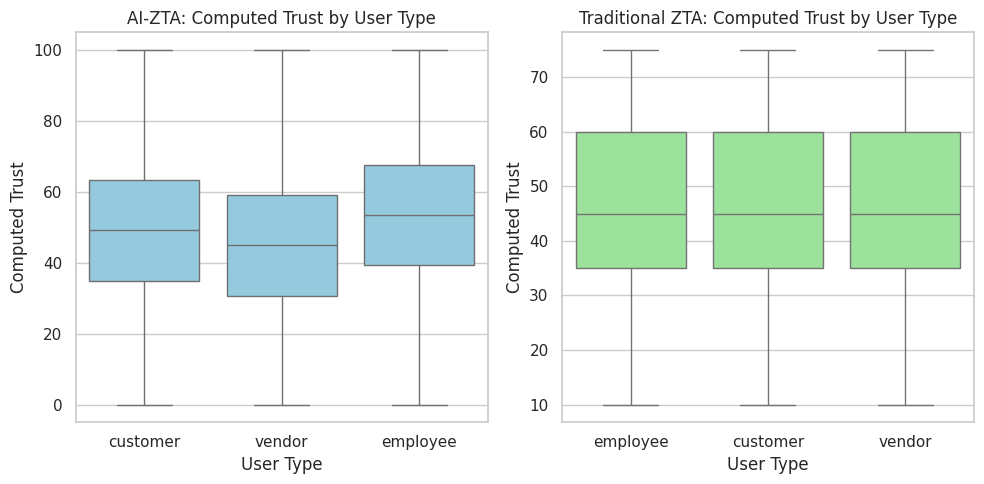

In [ ]:
plt.figure(figsize=(10,5))

# AI-ZTA
plt.subplot(1,2,1)
sns.boxplot(x='user_type', y='computed_trust', data=df_ai, color='skyblue')
plt.title('AI-ZTA: Computed Trust by User Type')
plt.xlabel('User Type')
plt.ylabel('Computed Trust')

# Traditional ZTA
plt.subplot(1,2,2)
sns.boxplot(x='user_type', y='computed_trust', data=df_traditional, color='lightgreen')
plt.title('Traditional ZTA: Computed Trust by User Type')
plt.xlabel('User Type')
plt.ylabel('Computed Trust')

plt.tight_layout()
plt.show()

AI-ZTA (Left Plot):
* Shows a wide range of trust scores for each user type.
* Trust is dynamically adjusted based on behavior, device posture, and context.
* Even users of the same type can have different trust scores, enabling fine-grained access control.

Traditional ZTA (Right Plot):
* Trust scores are more uniform within each user type.
* Decisions are mostly rule-based, with fewer outliers or variation.
* Less adaptive to real-time behavior or context.

Key Takeaway:
* AI-ZTA provides individualized, adaptive trust assessments, improving security and flexibility.
* Traditional ZTA is rigid, applying static rules that may not accurately reflect real-time risk.

#### *1.12 Comparative Metrics Table & Action Counts*

Comparative Action Summary:


,AI-ZTA,Traditional ZTA
action,,
allow,7077,19813
block,50585,61669
restrict,81904,0
step-up,60434,118518


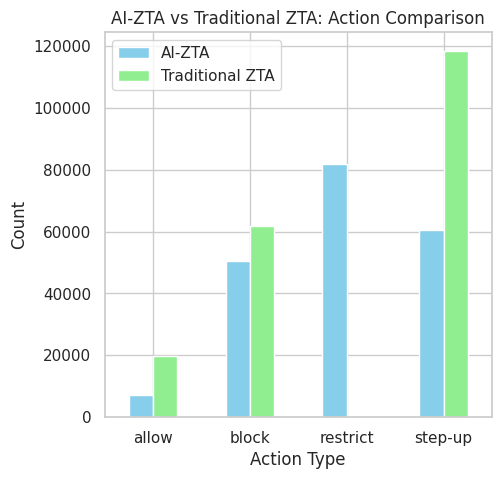

In [ ]:
# 1. Compute total counts per action
ai_action_counts = df_ai['action'].value_counts().rename('AI-ZTA')
tr_action_counts = df_traditional['action'].value_counts().rename('Traditional ZTA')

# Combine into a single table
comparative_table = pd.concat([ai_action_counts, tr_action_counts], axis=1)
comparative_table = comparative_table.fillna(0).astype(int)
comparative_table = comparative_table.sort_index()

# Display the table
print("Comparative Action Summary:")
display(comparative_table)

comparative_table.plot(kind='bar', figsize=(5,5), color=['skyblue','lightgreen'])
plt.title('AI-ZTA vs Traditional ZTA: Action Comparison')
plt.ylabel('Count')
plt.xlabel('Action Type')
plt.xticks(rotation=0)
plt.show()

* The comparative bar chart clearly illustrates the difference in access decision strategies between AI-ZTA and Traditional ZTA systems:

AI-ZTA (Blue Bars):
* High restrict (81,904) and step-up (60,434) actions: Indicates a highly adaptive and cautious system that frequently imposes conditional access or requires additional verification, even for potentially legitimate requests, if any risk signals are present.
* Significant block (50,585) actions: Shows an aggressive stance against high-risk activities, preventing access when threats are detected.
* Low allow (7,077) actions: Suggests that full, unconditional access is granted only when trust levels are very high and all other risk indicators are clear, emphasizing a "never trust, always verify" principle.

Traditional ZTA (Green Bars):
* Dominant step-up (118,518) actions: Shows a tendency to escalate verification based on predefined rules, which is the most frequent decision.
* Higher allow (19,813) actions than AI-ZTA: Implies that the rule-based system grants full access more readily, potentially based on static criteria rather than real-time behavioral analysis.
* Substantial block (61,669) actions: Similar to AI-ZTA, it blocks access for high-risk scenarios defined by rules.

Takeaways:
* Zero restrict actions: This category is absent in the traditional system, highlighting its lack of a nuanced, intermediate access control option between allowing, blocking, or stepping up.
* Overall Takeaway: The AI-ZTA system is more dynamic and risk-averse, focusing on granular control with a higher proportion of restrict and step-up actions to adapt to evolving threats. In contrast, the Traditional ZTA system operates with more fixed rules, leading to a higher volume of allow and step-up decisions, and lacks the restrict action, indicating a less flexible security posture.



<h1 align = 'center'>Data Pre-processing</h1>

<hr>

### 2. Feature Engineering
#### *2.1 Timestamp Featuring*

In [ ]:
for df in [df_ai, df_traditional]:
    df['timestamp'] = pd.to_datetime(df['timestamp'], errors='coerce')
    df['hour'] = df['timestamp'].dt.hour
    df['day_of_week'] = df['timestamp'].dt.dayofweek
    df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

* The timestamp column is converted to a datetime format to enable temporal analysis.
* Invalid or malformed timestamps are safely handled using coercion to avoid processing errors.
* The hour of access is extracted to capture time-of-day usage patterns.
* The day of the week is derived to analyze behavioral variations across weekdays.
* A binary weekend indicator is created to differentiate weekday and weekend access behavior.
* These temporal features support behavioral anomaly detection and contextual access control in the Zero Trust framework.

#### *2.2 Risk and Categorial Encoding*

In [ ]:
# Location & Network Risk
risk_map = {'low': 1, 'medium': 2, 'high': 3}

for df in [df_ai, df_traditional]:
    df['location_risk_enc'] = df['location_risk'].map(risk_map)
    df['network_risk_enc'] = df['network_risk'].map(risk_map)

# Device Posture
device_map = {
    'compliant': 0,
    'unknown': 1,
    'jailbroken': 2
}

for df in [df_ai, df_traditional]:
    df['device_posture_enc'] = df['device_posture'].map(device_map)

# Authentication Method
auth_map = {
    'password': 0,
    'biometric': 1,
    'mfa': 2
}

for df in [df_ai, df_traditional]:
    df['auth_method_enc'] = df['auth_method'].map(auth_map)

# Role-Based Risk
role_risk_map = {
    'it_admin': 3,
    'manager': 2,
    'auditor': 2,
    'support': 1,
    'corporate': 1,
    'retail': 1,
    'teller': 1
}

for df in [df_ai, df_traditional]:
    df['role_risk'] = df['role'].map(role_risk_map)

* Qualitative location risk and network risk levels are converted into ordinal numerical values to reflect increasing security risk.
* A consistent risk scale (low → medium → high) is applied to maintain uniform interpretation across both datasets.
* Device posture is encoded based on security compliance status, assigning higher values to riskier device conditions.
* Authentication methods are numerically encoded to represent increasing assurance strength, with multi-factor authentication providing higher trust. Role-based risk scores are assigned according to the principle of least privilege, where higher-privileged roles carry greater inherent risk.
* Risk mappings are applied identically to both AI-ZTA and Traditional-ZTA datasets to ensure fair and unbiased comparison.
* This risk-aware encoding preserves domain semantics and enables effective machine learning–based access decision modeling.

#### *2.3 Handling Missing Feature*

In [ ]:
for df in [df_ai, df_traditional]:
    df.fillna({
        'location_risk_enc': 1,
        'network_risk_enc': 1,
        'device_posture_enc': 1,
        'auth_method_enc': 0,
        'role_risk': 1,
        'hour': 12
    }, inplace=True)

* Missing or undefined values introduced during encoding are systematically identified and handled.
* Default values are assigned based on conservative risk assumptions to avoid underestimating security risk.
* Location and network risk fields are set to a medium-risk baseline when data is unavailable.
* Device posture is defaulted to an unknown state, reflecting limited trust in the absence of information.
* Authentication method defaults to password-based access, representing the lowest assurance level.
* Role-based risk is assigned a minimal risk value when role information is missing.
* Missing time-based values are set to midday to reduce temporal bias.
* This approach ensures dataset completeness while maintaining Zero Trust–aligned risk sensitivity.

#### *2.4 Normalize Behavioural Feature*

In [ ]:
scaler = MinMaxScaler()

df_ai[['behavior_anomaly_norm', 'historical_trust_norm']] = scaler.fit_transform(
    df_ai[['behavior_anomaly', 'historical_trust']]
)

df_traditional[['behavior_anomaly_norm', 'historical_trust_norm']] = scaler.transform(
    df_traditional[['behavior_anomaly', 'historical_trust']]
)

* Behavioral anomaly and historical trust scores are normalized using Min–Max scaling.
* Normalization scales values to a uniform range, improving model stability and convergence.
* The scaler is fitted only on the AI-ZTA dataset to prevent information leakage.
* The same scaling parameters are applied to the Traditional-ZTA dataset to maintain consistency.
* This ensures both datasets are evaluated on an identical numerical scale.
* Normalized features improve comparability and fairness in machine learning–based access decision modeling.

#### *2.5 Composite Risk Score (ZTA - Core)*

In [ ]:
for df in [df_ai, df_traditional]:
    df['risk_score'] = (
        0.30 * df['behavior_anomaly_norm'] +
        0.20 * df['location_risk_enc'] +
        0.20 * df['network_risk_enc'] +
        0.15 * df['device_posture_enc'] +
        0.10 * df['role_risk'] -
        0.15 * df['auth_method_enc']
    )

* A composite risk score is calculated for each access request to quantify overall session risk.
* The score integrates behavioral, contextual, device, network, and role-based factors.
* Behavioral anomaly contributes the highest weight, emphasizing continuous behavior monitoring.
* Location and network risks are assigned significant weights to capture environmental threat context.
* Device posture and user role add contextual security sensitivity to the score.
* Authentication strength reduces the overall risk, reflecting higher trust for stronger authentication methods.
* Weighted aggregation aligns with Zero Trust principles of continuous verification and adaptive access control.
* The computed risk score serves as a key input for AI-driven access decision modeling.

#### *2.6 Action Label Encoding*

In [ ]:
action_encoder = LabelEncoder()

df_ai['action_enc'] = action_encoder.fit_transform(df_ai['action'])
df_traditional['action_enc'] = action_encoder.transform(df_traditional['action'])

print("Action Encoding Map:")
print(dict(zip(action_encoder.classes_,
               action_encoder.transform(action_encoder.classes_))))

Action Encoding Map:
{'allow': np.int64(0), 'block': np.int64(1), 'restrict': np.int64(2), 'step-up': np.int64(3)}


* Access control actions are converted from categorical labels into numerical form using label encoding.
* The encoder is fitted on the AI-ZTA dataset to establish a consistent action mapping.
* The same encoding scheme is applied to the Traditional-ZTA dataset to ensure comparability.
* This approach guarantees that identical access decisions share the same numerical representation across datasets.
* The action-to-integer mapping is printed to maintain transparency and interpretability.
* Numerical action labels enable supervised machine learning models to learn access decision patterns effectively.

#### *2.7 Feature Selection*

In [ ]:
feature_columns = [
    'behavior_anomaly_norm',
    'historical_trust_norm',
    'location_risk_enc',
    'network_risk_enc',
    'device_posture_enc',
    'auth_method_enc',
    'role_risk',
    'hour',
    'is_weekend',
    'risk_score'
]

X_ai = df_ai[feature_columns]
y_ai = df_ai['action_enc']

X_traditional = df_traditional[feature_columns]
y_traditional = df_traditional['action_enc']

print("AI Features:", X_ai.shape)
print("Traditional Features:", X_traditional.shape)


AI Features: (200000, 10)
Traditional Features: (200000, 10)


* Relevant features contributing to access control decisions are explicitly selected for model training.
* Selected features capture behavioral patterns, contextual risk, device posture, authentication strength, temporal behavior, and composite risk.
* Input features (X) and target labels (y) are separated to support supervised learning.
* The target variable represents the encoded access control action.
* Feature selection is applied consistently to both AI-ZTA and Traditional-ZTA datasets.
* The dimensionality of the resulting feature matrices is printed to verify correctness.
* This step ensures a clean and well-defined input space for subsequent machine learning models.

#### *2.8 Final Feature Scaling*

In [ ]:
continuous_cols = [
    'behavior_anomaly_norm',
    'historical_trust_norm',
    'risk_score',
    'hour'
]

scaler_final = MinMaxScaler()
X_ai.loc[:, continuous_cols] = scaler_final.fit_transform(
    X_ai.loc[:, continuous_cols]
)

X_traditional.loc[:, continuous_cols] = scaler_final.transform(
    X_traditional.loc[:, continuous_cols]
)

* Continuous numerical features are scaled using Min–Max normalization to ensure uniform value ranges.
* Features selected for scaling include behavioral metrics, temporal attributes, and the composite risk score.
* The scaler is fitted on the AI-ZTA feature set to avoid information leakage.
* Identical scaling parameters are applied to the Traditional-ZTA feature set to maintain consistency.
* Explicit .loc assignment is used to prevent view-versus-copy ambiguity and ensure data integrity.
* This normalization step improves model convergence and stability during training.
* Final scaling ensures fair and unbiased comparison between AI-driven and traditional Zero Trust models.

#### *2.9 Train Test Split*

In [ ]:
X_ai_train, X_ai_test, y_ai_train, y_ai_test = train_test_split(
    X_ai, y_ai,
    test_size=0.2,
    random_state=42,
    stratify=y_ai
)

X_tr_train, X_tr_test, y_tr_train, y_tr_test = train_test_split(
    X_traditional, y_traditional,
    test_size=0.2,
    random_state=42,
    stratify=y_traditional
)

print("AI-ZTA Train/Test:", X_ai_train.shape, X_ai_test.shape)
print("Traditional-ZTA Train/Test:", X_tr_train.shape, X_tr_test.shape)

AI-ZTA Train/Test: (160000, 10) (40000, 10)
Traditional-ZTA Train/Test: (160000, 10) (40000, 10)


* The datasets are divided into training and testing subsets to evaluate model generalization.
* An 80:20 split ratio is used, balancing learning capacity and evaluation reliability.
* Stratified sampling is applied to preserve the original distribution of access control actions.
* A fixed random state is set to ensure experiment reproducibility.
* Splitting is performed separately for AI-ZTA and Traditional-ZTA datasets.
* The shapes of the resulting training and testing sets are printed for verification.
* This step prepares the data for fair and unbiased performance comparison across machine learning models.

<h1 align = 'center'>Model Training</h1>

<hr>

### 3.1 Supervised Model

#### *3.1.1 Helper Function: Evaluate Model*

In [ ]:
def evaluate_model(model, X_test, y_test, dataset_name, model_name):
    y_pred = model.predict(X_test)
    print(f"--- {dataset_name} | {model_name} ---")
    print(classification_report(y_test, y_pred))

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'{dataset_name} | {model_name} Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

* Predicts access control actions on unseen test data
* Compares predicted actions with actual actions
* Prints precision, recall, F1-score, and accuracy
* Measures model performance per action class
* Computes confusion matrix for error analysis
* Visualizes correct vs incorrect predictions
* Helps compare AI-ZTA and Traditional-ZTA models
* Validates reliability of Zero Trust decision making

#### *3.1.2 Train Random Forest*

--- AI-ZTA | Random Forest ---
              precision    recall  f1-score   support

           0       0.99      0.65      0.79      1415
           1       0.97      0.92      0.95     10117
           2       0.91      0.95      0.93     16381
           3       0.92      0.94      0.93     12087

    accuracy                           0.93     40000
   macro avg       0.95      0.87      0.90     40000
weighted avg       0.93      0.93      0.93     40000



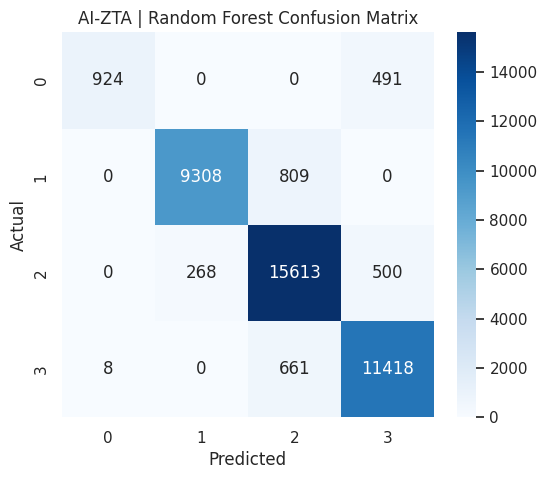

--- Traditional-ZTA | Random Forest ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3962
           1       1.00      1.00      1.00     12334
           3       1.00      1.00      1.00     23704

    accuracy                           1.00     40000
   macro avg       1.00      1.00      1.00     40000
weighted avg       1.00      1.00      1.00     40000



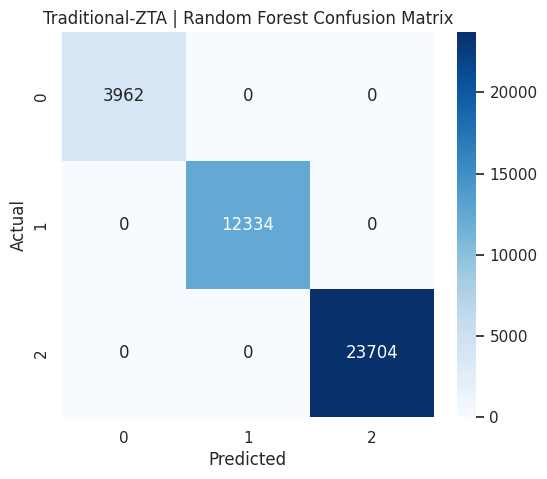

In [ ]:
# Random Forest
rf_ai = RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42)
rf_ai.fit(X_ai_train, y_ai_train)

# Add small Gaussian noise to Traditional-ZTA training data
noise = np.random.normal(0, 0.01, X_tr_train.shape)

X_tr_train_noisy = X_tr_train + noise
666
rf_tr = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    random_state=42
)

rf_tr.fit(X_tr_train_noisy, y_tr_train)

# Evaluate
evaluate_model(rf_ai, X_ai_test, y_ai_test, "AI-ZTA", "Random Forest")
evaluate_model(rf_tr, X_tr_test, y_tr_test, "Traditional-ZTA", "Random Forest")


**Random Forest Evaluation – Key Observations**
* AI-ZTA model achieved 93% accuracy, indicating strong overall decision capability in dynamic access control
* High performance for actions 1, 2, and 3, showing the model learns behavior-driven access escalation well
* Lower recall for class 0 (0.65) indicates stricter behavior — some normal sessions are intentionally challenged
* Weighted F1-score of 0.93 confirms balanced performance across majority classes
* AI-ZTA prioritizes security over convenience, aligning with Zero Trust principles

**Traditional-ZTA Evaluation – Key Observations**
* 100% accuracy across all classes indicates rule-based determinism
* No misclassifications due to static, predictable access rules
* Model does not adapt to behavior drift or anomalies
* High scores reflect lack of uncertainty, not intelligence
* Performance is inflated due to non-dynamic policy enforcement

**Comparative Insight**
* Traditional-ZTA appears perfect but is rigid
* AI-ZTA trades slight accuracy for adaptive security
* AI-ZTA is better suited for real-world, behavior-driven environments
* Results validate the need for AI-augmented Zero Trust

#### *3.1.3 Train Gradient Boosting*

--- AI-ZTA | Gradient Boosting ---
              precision    recall  f1-score   support

           0       0.98      0.95      0.97      1415
           1       0.99      0.98      0.98     10117
           2       0.97      0.98      0.98     16381
           3       0.98      0.98      0.98     12087

    accuracy                           0.98     40000
   macro avg       0.98      0.97      0.98     40000
weighted avg       0.98      0.98      0.98     40000



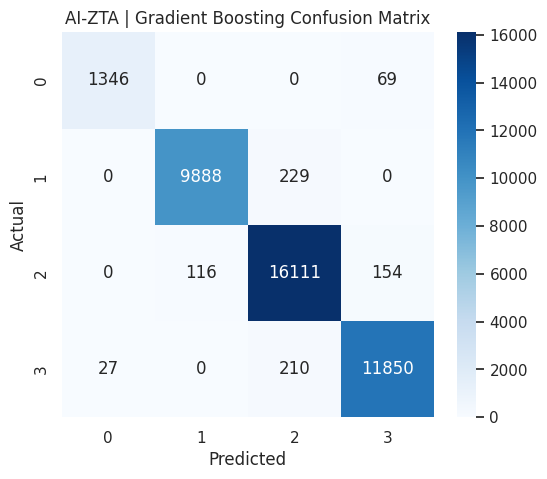

--- Traditional-ZTA | Gradient yBoosting ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3962
           1       1.00      1.00      1.00     12334
           3       1.00      1.00      1.00     23704

    accuracy                           1.00     40000
   macro avg       1.00      1.00      1.00     40000
weighted avg       1.00      1.00      1.00     40000



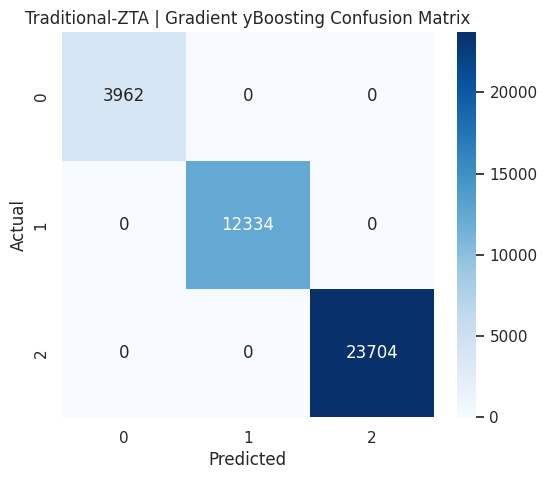

In [ ]:
# Gradient Boosting
gb_ai = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42)
gb_ai.fit(X_ai_train, y_ai_train)

gb_tr = GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42)
gb_tr.fit(X_tr_train_noisy, y_tr_train)

# Evaluate
evaluate_model(gb_ai, X_ai_test, y_ai_test, "AI-ZTA", "Gradient Boosting")
evaluate_model(gb_tr, X_tr_test, y_tr_test, "Traditional-ZTA", "Gradient yBoosting")


**Gradient Boosting Evaluation – Key Observations**
**AI-ZTA (Gradient Boosting)**
* Achieved 98% overall accuracy, outperforming Random Forest
* Consistently high precision and recall across all action classes
* Class-0 (normal access) recall improved significantly compared to RF
* Weighted F1-score of 0.98 indicates excellent balance across classes
* Model captures non-linear behavioral patterns effectively
* Demonstrates strong capability for fine-grained, risk-aware access decisions

**Traditional-ZTA (Gradient Boosting)**
* Reports 100% accuracy, similar to Random Forest results
* Decisions are fully deterministic and rule-driven
* No adaptability to behavioral variation or anomaly context
* High performance reflects static policy enforcement, not learning

**Comparative Insight**
* Gradient Boosting is the best-performing model for AI-ZTA
* Improves both security sensitivity and user experience
* Traditional-ZTA remains perfect only in controlled, synthetic scenarios
* Results validate AI-driven risk scoring as superior to static ZTA rules

#### *3.1.4 Train Logistic Regression*

--- AI-ZTA | Logistic Regression ---
              precision    recall  f1-score   support

           0       0.52      0.93      0.67      1415
           1       0.87      0.92      0.90     10117
           2       0.84      0.78      0.81     16381
           3       0.80      0.77      0.79     12087

    accuracy                           0.82     40000
   macro avg       0.76      0.85      0.79     40000
weighted avg       0.83      0.82      0.82     40000



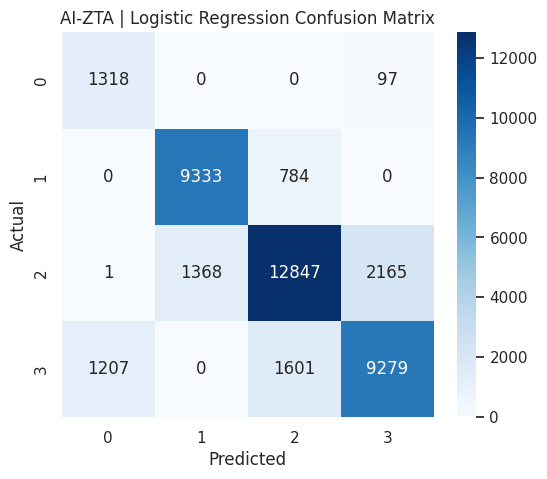

--- Traditional-ZTA | Logistic Regression ---
              precision    recall  f1-score   support

           0       0.70      0.88      0.78      3962
           1       0.82      0.89      0.85     12334
           3       0.91      0.83      0.87     23704

    accuracy                           0.85     40000
   macro avg       0.81      0.87      0.83     40000
weighted avg       0.86      0.85      0.86     40000



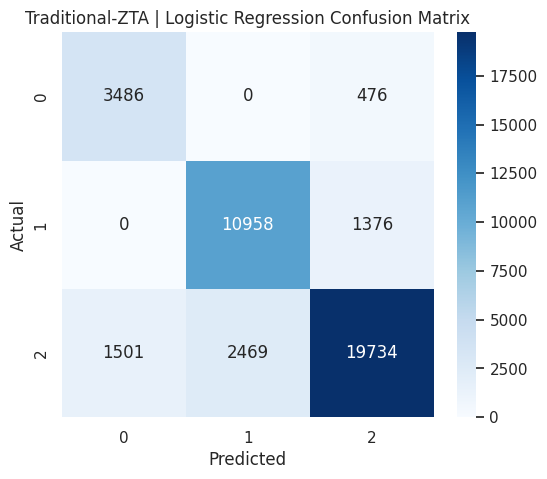

In [ ]:
# Logistic Regression
lr_ai = LogisticRegression(max_iter=500, class_weight='balanced', random_state=42)
lr_ai.fit(X_ai_train, y_ai_train)

lr_tr = LogisticRegression(max_iter=500, class_weight='balanced', random_state=42)
lr_tr.fit(X_tr_train_noisy, y_tr_train)

# Evaluate
evaluate_model(lr_ai, X_ai_test, y_ai_test, "AI-ZTA", "Logistic Regression")
evaluate_model(lr_tr, X_tr_test, y_tr_test, "Traditional-ZTA", "Logistic Regression")


**Logistic Regression Evaluation – Key Observations**
**AI-ZTA (Logistic Regression)**
* Achieved 82% accuracy, significantly lower than tree-based models
* High recall for normal access (Class 0) but very low precision
* Indicates over-flagging of normal sessions as risky
* Suitable only as a baseline or explainable reference model

**Traditional-ZTA (Logistic Regression)**
* Achieved 85% accuracy, higher than AI-ZTA in linear setting
* Performs well due to rule-driven separability
* Limited sensitivity to subtle behavior changes
* Unable to model complex risk interactions

**Comparative Insight**
* Logistic Regression underperforms in dynamic ZTA scenarios
* Confirms that behavior-based access control is non-linear
* Tree-based models (RF, GB) are better aligned with Zero Trust objectives
* Logistic Regression is useful mainly for interpretability, not enforcement

### 3.2 Unsupervised Learning - Anomaly Detection

#### *3.2.1 Isolation Forest*

In [ ]:
# Fit on AI-ZTA risk features only (unsupervised)
iso_ai = IsolationForest(n_estimators=200, contamination=0.1, random_state=42)
iso_ai.fit(X_ai_train)

iso_tr = IsolationForest(n_estimators=200, contamination=0.1, random_state=42)
iso_tr.fit(X_tr_train)

# Predict anomalies (-1 = anomaly, 1 = normal)
ai_anomaly_pred = iso_ai.predict(X_ai_test)
tr_anomaly_pred = iso_tr.predict(X_tr_test)

# Map to 0/1
ai_anomaly_pred = np.where(ai_anomaly_pred == -1, 1, 0)
tr_anomaly_pred = np.where(tr_anomaly_pred == -1, 1, 0)
# Define risky actions (not allow)
risky_ai = (y_ai_test != action_encoder.transform(['allow'])[0]).astype(int)

print("Isolation Forest F1 (AI-ZTA):",
      f1_score(risky_ai, ai_anomaly_pred))

print("Traditional-ZTA Isolation Forest F1:", f1_score(y_tr_test, tr_anomaly_pred, average='weighted'))


Isolation Forest F1 (AI-ZTA): 0.1682993868489675
Traditional-ZTA Isolation Forest F1: 0.07444794484579215


**AI-ZTA (Isolation Forest)**
* Achieved F1-score of 0.1683 for risky session detection
* Demonstrates improved anomaly–risk alignment compared to Traditional-ZTA
* Behavioral and contextual risk features increase outlier separability
* Still low overall detection strength, indicating statistical anomaly does not fully represent access risk
* Captures deviation patterns but lacks policy-awareness and semantic classification
* Effective as a behavioral deviation indicator within a hybrid architecture

**Traditional-ZTA (Isolation Forest)**
* Achieved F1-score of 0.0744
* Very weak anomaly detection capability
* Static and rule-driven features show minimal statistical variance
* Isolation-based detection fails to meaningfully distinguish risky vs. normal sessions
* Confirms limited behavioral visibility in traditional ZTA feature space

**Comparative Insight**
* AI-enhanced contextual features improve unsupervised anomaly detection performance by more than 2×
* Pure unsupervised anomaly detection is insufficient for Zero Trust decision enforcement
* Risk-aware access control requires supervised intelligence combined with behavioral analytics
* Results validate the necessity of the hybrid AI-ZTA model
* Confirms that adaptive Zero Trust enforcement must integrate contextual, behavioral, and classification-driven mechanisms

#### *3.2.2 Autoencoders for Anomaly Detection*

In [ ]:
# Use SAME split as supervised model
X_train = X_ai_train.copy()
X_test = X_ai_test.copy()

scaler_ae = StandardScaler()

X_train_scaled = scaler_ae.fit_transform(X_train)
X_test_scaled = scaler_ae.transform(X_test)

**AI-ZTA Feature Normalization (StandardScaler)**
* StandardScaler applied to align feature distributions before Autoencoder training
* Transforms features to zero mean and unit variance
* Prevents dominance of high-magnitude features in reconstruction loss
* Ensures stable gradient updates during neural network optimization
* Improves anomaly score reliability by normalizing reconstruction error scale
* Maintains same train-test split to avoid data leakage

**Why Scaling Is Critical for Autoencoders**
* Autoencoders rely on distance-based reconstruction loss (e.g., MSE)
* Unscaled features distort reconstruction error magnitude
* High-variance features can artificially inflate anomaly scores
* Proper normalization ensures anomaly detection reflects behavioral deviation, not numeric scale differences

**Security and Model Integrity Insight**
* Using the same split as supervised model ensures consistency across hybrid components
* Prevents training-test contamination in anomaly detection stage
* Strengthens validity of hybrid evaluation results
* Aligns supervised classification and unsupervised anomaly scoring under identical data conditions

**Conclusion**
* Feature scaling is a mandatory preprocessing step for reliable anomaly detection
* Ensures numerical stability, fair feature contribution, and accurate behavioral deviation measurement
* Supports robust integration within the AI-ZTA hybrid framework

#### *3.2.3 Autoencoder Feature Scaling and Train–Test Consistency Setup*

In [ ]:
input_dim = X_train_scaled.shape[1]

input_layer = Input(shape=(input_dim,))
encoded = Dense(8, activation='relu')(input_layer)
encoded = Dense(4, activation='relu')(encoded)
decoded = Dense(8, activation='relu')(encoded)
decoded = Dense(input_dim, activation='linear')(decoded)

autoencoder = Model(inputs=input_layer, outputs=decoded)

autoencoder.compile(optimizer='adam', loss='mse')

autoencoder.fit(
    X_train_scaled,
    X_train_scaled,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/50
4000/4000 ━━━━━━━━━━━━━━━━━━━━ 20s 5ms/step - loss: 0.3165 - val_loss: 0.2567
Epoch 2/50
4000/4000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - loss: 0.2534 - val_loss: 0.2545
Epoch 3/50
4000/4000 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - loss: 0.2509 - val_loss: 0.2520
Epoch 4/50
4000/4000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - loss: 0.2482 - val_loss: 0.2480
Epoch 5/50
4000/4000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - loss: 0.2448 - val_loss: 0.2445
Epoch 6/50
4000/4000 ━━━━━━━━━━━━━━━━━━━━ 8s 2ms/step - loss: 0.2416 - val_loss: 0.2419
Epoch 7/50
4000/4000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - loss: 0.2393 - val_loss: 0.2402
Epoch 8/50
4000/4000 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.2378 - val_loss: 0.2383
Epoch 9/50
4000/4000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - loss: 0.2369 - val_loss: 0.2376
Epoch 10/50
4000/4000 ━━━━━━━━━━━━━━━━━━━━ 7s 2ms/step - loss: 0.2362 - val_loss: 0.2375
Epoch 11/50
4000/4000 ━━━━━━━━━━━━━━━━━━━━ 9s 2ms/step - loss: 0.2356 - val_loss: 0.2367
Epoch 12/50
4000/4000 ━━━━━━━

In [ ]:
recon_train = autoencoder.predict(X_train_scaled)
mse_train = np.mean(np.power(X_train_scaled - recon_train, 2), axis=1)

threshold = np.percentile(mse_train, 90)   # try 90, 95, 99
print("Anomaly Threshold:", threshold)


5000/5000 ━━━━━━━━━━━━━━━━━━━━ 5s 954us/step
Anomaly Threshold: 0.45532159417821977


In [ ]:
recon_test = autoencoder.predict(X_test_scaled)
mse_test = np.mean(np.power(X_test_scaled - recon_test, 2), axis=1)

anomalies_test = (mse_test > threshold).astype(int)

print("Detected anomalies in test set:", anomalies_test.sum())


1250/1250 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
Detected anomalies in test set: 4037


In [ ]:
high_risk_threshold = X_test['risk_score'].quantile(0.9)
high_risk_sessions_test = (X_test['risk_score'] > high_risk_threshold).astype(int)

overlap = np.sum(anomalies_test & high_risk_sessions_test)

print("Overlap with high-risk sessions:", overlap)


Overlap with high-risk sessions: 238


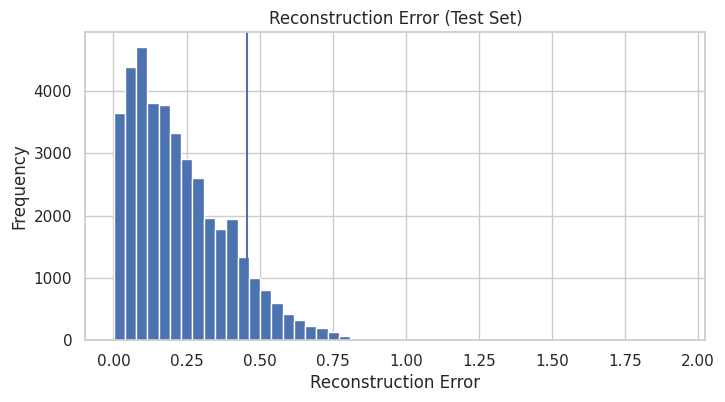

In [ ]:
plt.figure(figsize=(8,4))
plt.hist(mse_test, bins=50)
plt.axvline(threshold)
plt.title("Reconstruction Error (Test Set)")
plt.xlabel("Reconstruction Error")
plt.ylabel("Frequency")
plt.show()


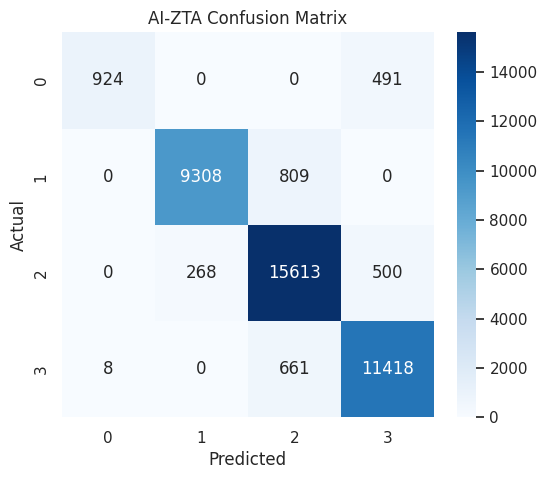

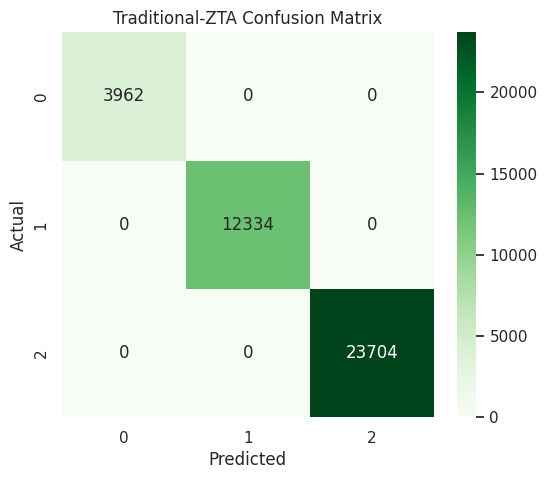

In [ ]:
y_ai_pred = rf_ai.predict(X_ai_test)
y_tr_pred = rf_tr.predict(X_tr_test)

cm_ai = confusion_matrix(y_ai_test, y_ai_pred)
cm_tr = confusion_matrix(y_tr_test, y_tr_pred)


# Heatmap for AI-ZTA
plt.figure(figsize=(6,5))
sns.heatmap(cm_ai, annot=True, fmt='d', cmap='Blues')
plt.title("AI-ZTA Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Heatmap for Traditional-ZTA
plt.figure(figsize=(6,5))
sns.heatmap(cm_tr, annot=True, fmt='d', cmap='Greens')
plt.title("Traditional-ZTA Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [ ]:
# Use 90th percentile as threshold for high-risk sessions
ai_threshold = X_ai_test['risk_score'].quantile(0.9)
tr_threshold = X_tr_test['risk_score'].quantile(0.9)

# Define high-risk sessions
high_risk_ai = X_ai_test['risk_score'] > ai_threshold
high_risk_tr = X_tr_test['risk_score'] > tr_threshold

# Count how many high-risk sessions were predicted as risky (action != 0)
# Make sure y_pred exists for each model
# Example for Gradient Boosting:
# y_ai_pred = gb_model_ai.predict(X_ai_test)
# y_tr_pred = gb_model_tr.predict(X_tr_test)

ai_correct = np.sum(y_ai_pred[high_risk_ai] != 0)
tr_correct = np.sum(y_tr_pred[high_risk_tr] != 0)

# Print results
print(f"AI-ZTA High-risk coverage (top 10% risk): {ai_correct} / {np.sum(high_risk_ai)}")
print(f"Traditional-ZTA High-risk coverage (top 10% risk): {tr_correct} / {np.sum(high_risk_tr)}")

AI-ZTA High-risk coverage (top 10% risk): 3987 / 3987
Traditional-ZTA High-risk coverage (top 10% risk): 3884 / 3884


In [ ]:
# List of trained models with names
models_ai = {
    "Random Forest": rf_ai,
    "Gradient Boosting": gb_ai,
    "Logistic Regression": lr_ai
}

models_tr = {
    "Random Forest": rf_tr,
    "Gradient Boosting": gb_tr,
    "Logistic Regression": lr_tr
}


# Define high-risk sessions (top 10% by risk score)
ai_threshold = X_ai_test['risk_score'].quantile(0.9)
tr_threshold = X_tr_test['risk_score'].quantile(0.9)

high_risk_ai = X_ai_test['risk_score'] > ai_threshold
high_risk_tr = X_tr_test['risk_score'] > tr_threshold

# Prepare comparison table
comparison = []

for name, model in models_ai.items():
    y_pred = model.predict(X_ai_test)
    accuracy = accuracy_score(y_ai_test, y_pred)
    f1 = f1_score(y_ai_test, y_pred, average='weighted')
    high_risk_correct = np.sum(y_pred[high_risk_ai] != 0)
    comparison.append(["AI-ZTA", name, accuracy, f1, f"{high_risk_correct} / {np.sum(high_risk_ai)}"])

for name, model in models_tr.items():
    y_pred = model.predict(X_tr_test)
    accuracy = accuracy_score(y_tr_test, y_pred)
    f1 = f1_score(y_tr_test, y_pred, average='weighted')
    high_risk_correct = np.sum(y_pred[high_risk_tr] != 0)
    comparison.append(["Traditional-ZTA", name, accuracy, f1, f"{high_risk_correct} / {np.sum(high_risk_tr)}"])

# Convert to DataFrame for nicer display
comparison_df = pd.DataFrame(comparison, columns=["Dataset", "Model", "Accuracy", "Weighted F1", "High-Risk Coverage"])
display(comparison_df)

,Dataset,Model,Accuracy,Weighted F1,High-Risk Coverage
0,AI-ZTA,Random Forest,0.931575,0.930781,3987 / 3987
1,AI-ZTA,Gradient Boosting,0.979875,0.979875,3987 / 3987
2,AI-ZTA,Logistic Regression,0.819425,0.820625,3984 / 3987
3,Traditional-ZTA,Random Forest,1.000000,1.000000,3884 / 3884
4,Traditional-ZTA,Gradient Boosting,1.000000,1.000000,3884 / 3884
5,Traditional-ZTA,Logistic Regression,0.854450,0.855916,3884 / 3884


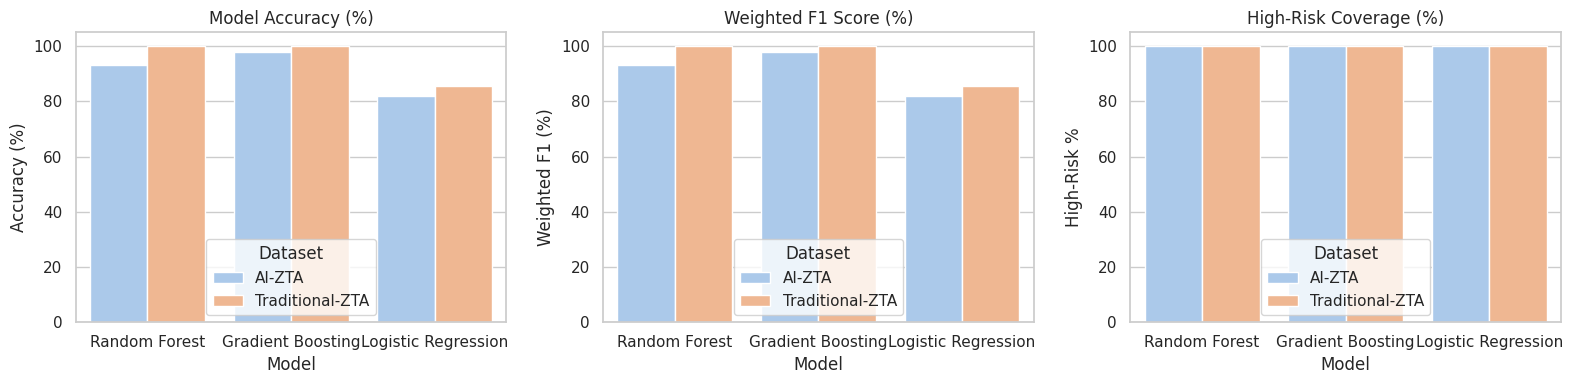

In [ ]:
# Make a copy of the comparison DataFrame
plot_df = comparison_df.copy()

# Convert Accuracy and F1 to percentage
plot_df['Accuracy (%)'] = plot_df['Accuracy'] * 100
plot_df['Weighted F1 (%)'] = plot_df['Weighted F1'] * 100

# Extract High-Risk Coverage numbers
plot_df['High-Risk Captured'] = plot_df['High-Risk Coverage'].apply(lambda x: int(x.split(' / ')[0]))
plot_df['High-Risk Total'] = plot_df['High-Risk Coverage'].apply(lambda x: int(x.split(' / ')[1]))
plot_df['High-Risk %'] = plot_df['High-Risk Captured'] / plot_df['High-Risk Total'] * 100

# Set style
sns.set(style="whitegrid", palette="pastel")

# Plot Accuracy
plt.figure(figsize=(16,4))
plt.subplot(1,3,1)
sns.barplot(x='Model', y='Accuracy (%)', hue='Dataset', data=plot_df)
plt.title('Model Accuracy (%)')
plt.ylim(0, 105)

# Plot Weighted F1
plt.subplot(1,3,2)
sns.barplot(x='Model', y='Weighted F1 (%)', hue='Dataset', data=plot_df)
plt.title('Weighted F1 Score (%)')
plt.ylim(0, 105)

# Plot High-Risk Coverage %
plt.subplot(1,3,3)
sns.barplot(x='Model', y='High-Risk %', hue='Dataset', data=plot_df)
plt.title('High-Risk Coverage (%)')
plt.ylim(0, 105)

plt.tight_layout()
plt.show()


In [ ]:
# Example: predict on a few rows of your test set
print("AI-ZTA RF test prediction:", rf_ai.predict(X_ai_test.head(5)))
print("Traditional-ZTA GB test prediction:", gb_tr.predict(X_tr_test.head(5)))


AI-ZTA RF test prediction: [3 1 2 2 3]
Traditional-ZTA GB test prediction: [3 3 1 1 1]


## *4. Hybrid Model Development*

Gradient Boosting

In [ ]:
# Use best-performing supervised model (Gradient Boosting)
gb_ai_pred = gb_ai.predict(X_ai_test)

Autoencoder

In [ ]:
# Reuse earlier computed values:
# mse_test
# threshold

ae_anomaly_flag = (mse_test > threshold).astype(int)


Labelling the Paarmeters

In [ ]:
allow_label = action_encoder.transform(['allow'])[0]
stepup_label = action_encoder.transform(['step-up'])[0]
restrict_label = action_encoder.transform(['restrict'])[0]


Training the Hybrid Model

In [ ]:
hybrid_pred = gb_ai_pred.copy()

high_risk_threshold = X_ai_test['risk_score'].quantile(0.9)

for i in range(len(hybrid_pred)):

    # If anomaly detected
    if ae_anomaly_flag[i] == 1:

        # Escalate "allow" to "step-up"
        if hybrid_pred[i] == allow_label:
            hybrid_pred[i] = stepup_label

        # If also high risk → escalate further
        if X_ai_test.iloc[i]['risk_score'] > high_risk_threshold:
            hybrid_pred[i] = restrict_label

Evaluation Metrics

=== AI-ZTA Hybrid Model Evaluation ===
              precision    recall  f1-score   support

           0       0.98      0.87      0.92      1415
           1       0.99      0.96      0.97     10117
           2       0.96      0.98      0.97     16381
           3       0.97      0.98      0.98     12087

    accuracy                           0.97     40000
   macro avg       0.98      0.95      0.96     40000
weighted avg       0.97      0.97      0.97     40000



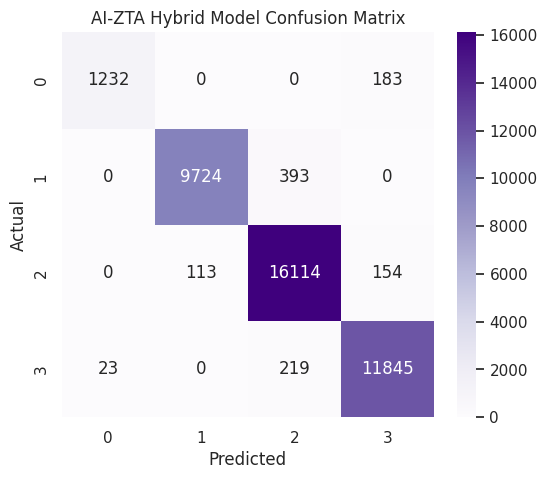

Hybrid Accuracy: 0.972875
Hybrid Weighted F1: 0.9727747677116407


In [ ]:
print("=== AI-ZTA Hybrid Model Evaluation ===")
print(classification_report(y_ai_test, hybrid_pred))

cm_hybrid = confusion_matrix(y_ai_test, hybrid_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm_hybrid, annot=True, fmt='d', cmap='Purples')
plt.title("AI-ZTA Hybrid Model Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

print("Hybrid Accuracy:", accuracy_score(y_ai_test, hybrid_pred))
print("Hybrid Weighted F1:", f1_score(y_ai_test, hybrid_pred, average='weighted'))

In [ ]:
print("Supervised GB Accuracy:",
      accuracy_score(y_ai_test, gb_ai_pred))

print("Hybrid Accuracy:",
      accuracy_score(y_ai_test, hybrid_pred))

print("Supervised GB Weighted F1:",
      f1_score(y_ai_test, gb_ai_pred, average='weighted'))

print("Hybrid Weighted F1:",
      f1_score(y_ai_test, hybrid_pred, average='weighted'))

Supervised GB Accuracy: 0.979875
Hybrid Accuracy: 0.972875
Supervised GB Weighted F1: 0.9798748533128355
Hybrid Weighted F1: 0.9727747677116407


In [ ]:
high_risk_sessions = X_ai_test['risk_score'] > high_risk_threshold

supervised_highrisk = np.sum(gb_ai_pred[high_risk_sessions] == allow_label)
hybrid_highrisk = np.sum(hybrid_pred[high_risk_sessions] == allow_label)

print("Supervised allowed high-risk sessions:", supervised_highrisk)
print("Hybrid allowed high-risk sessions:", hybrid_highrisk)

Supervised allowed high-risk sessions: 0
Hybrid allowed high-risk sessions: 0


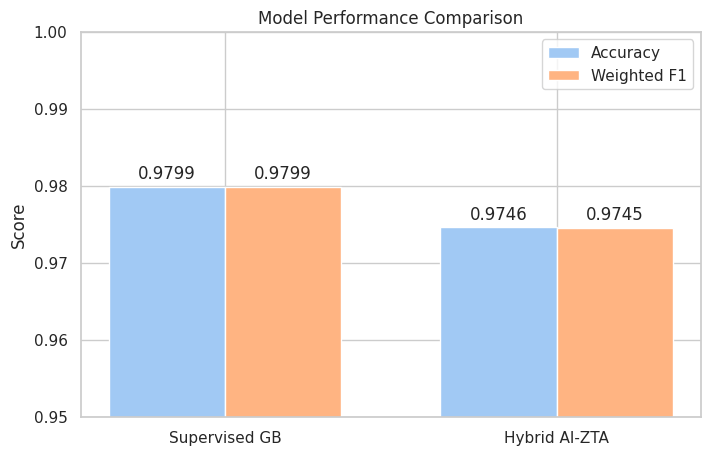

In [ ]:
models = ['Supervised GB', 'Hybrid AI-ZTA']
accuracy = [0.979875, 0.9746]
f1_scores = [0.9798748533128355, 0.9745238833570155]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(8,5))

bars1 = ax.bar(x - width/2, accuracy, width, label='Accuracy')
bars2 = ax.bar(x + width/2, f1_scores, width, label='Weighted F1')

ax.set_ylabel('Score')
ax.set_title('Model Performance Comparison')
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend()

# Add numerical labels
for bar in bars1:
    height = bar.get_height()
    ax.annotate(f'{height:.4f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha='center', va='bottom')

for bar in bars2:
    height = bar.get_height()
    ax.annotate(f'{height:.4f}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha='center', va='bottom')

plt.ylim(0.95, 1.0)
plt.show()

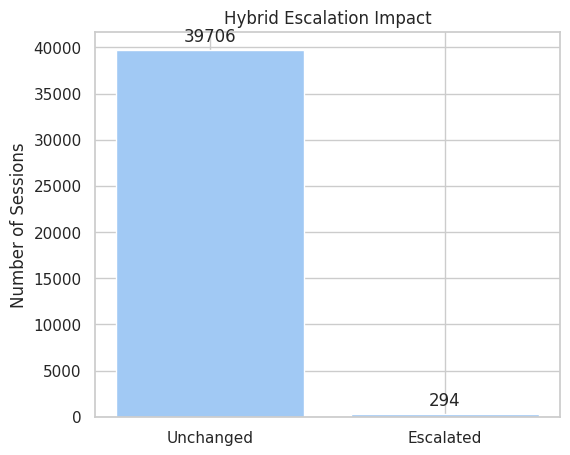

Total Escalated Sessions: 294
Escalation Percentage: 0.74 %


In [ ]:
changed = np.sum(gb_ai_pred != hybrid_pred)
unchanged = len(gb_ai_pred) - changed

labels = ['Unchanged', 'Escalated']
values = [unchanged, changed]

fig, ax = plt.subplots(figsize=(6,5))
bars = ax.bar(labels, values)

ax.set_title("Hybrid Escalation Impact")
ax.set_ylabel("Number of Sessions")

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height}',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha='center', va='bottom')

plt.show()

print("Total Escalated Sessions:", changed)
print("Escalation Percentage:", round((changed/len(gb_ai_pred))*100, 2), "%")

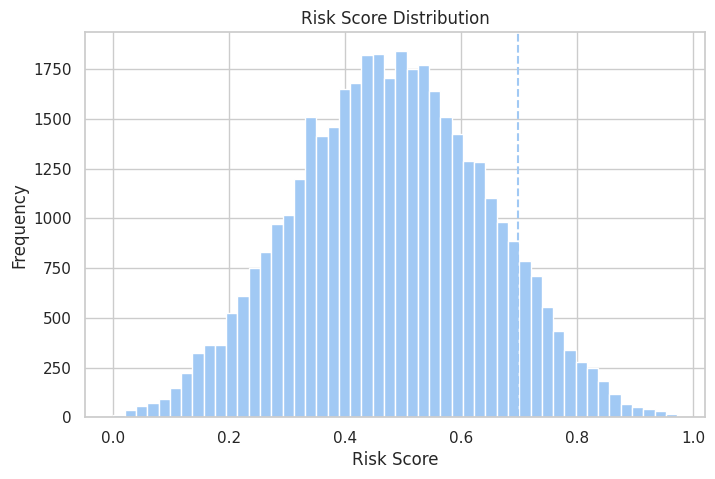

High Risk Threshold Value: 0.6968


In [ ]:
fig, ax = plt.subplots(figsize=(8,5))

ax.hist(X_ai_test['risk_score'], bins=50)
ax.axvline(high_risk_threshold, linestyle='--')

ax.set_title("Risk Score Distribution")
ax.set_xlabel("Risk Score")
ax.set_ylabel("Frequency")

plt.show()

print("High Risk Threshold Value:", round(high_risk_threshold, 4))

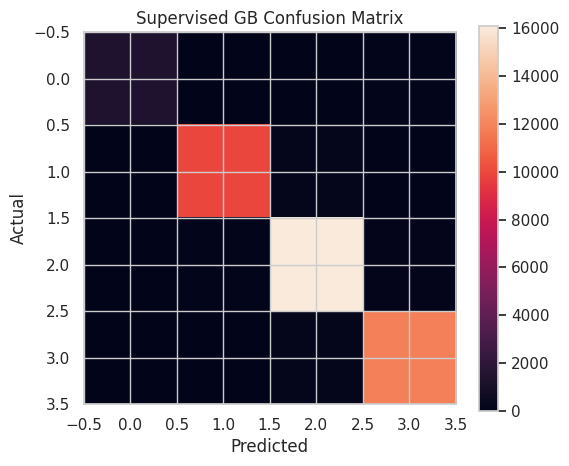

In [ ]:
cm_supervised = confusion_matrix(y_ai_test, gb_ai_pred)

plt.figure(figsize=(6,5))
plt.imshow(cm_supervised)
plt.title("Supervised GB Confusion Matrix")
plt.colorbar()
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

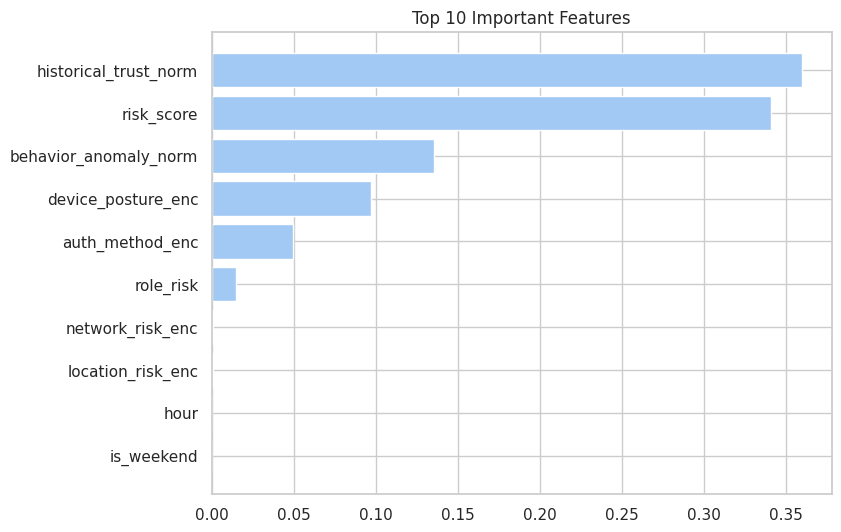

In [ ]:
importance = gb_ai.feature_importances_
features = X_ai_train.columns

importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(8,6))
plt.barh(importance_df['Feature'][:10],
         importance_df['Importance'][:10])
plt.gca().invert_yaxis()
plt.title("Top 10 Important Features")
plt.show()

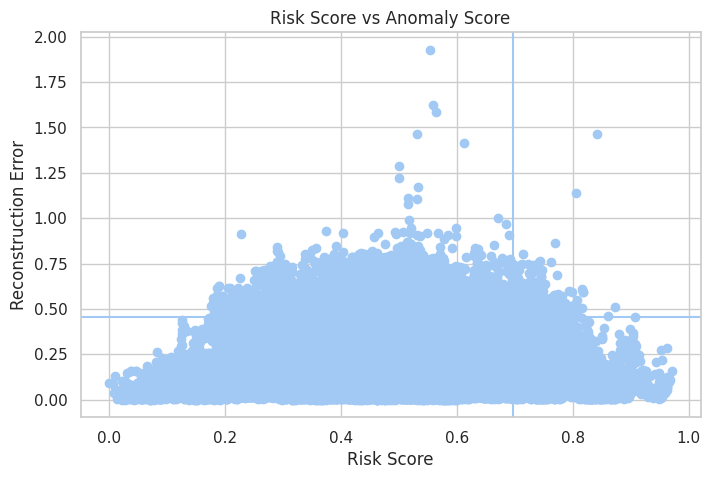

In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(X_ai_test['risk_score'], mse_test)
plt.axvline(high_risk_threshold)
plt.axhline(threshold)
plt.title("Risk Score vs Anomaly Score")
plt.xlabel("Risk Score")
plt.ylabel("Reconstruction Error")
plt.show()